# 01 - EDA HousingQA

Roadmap **Bước 1.1**: tải `questions` / `questions_aux`, thống kê tỉ lệ Yes/No, số câu mỗi bang, `question_group`, độ dài câu hỏi và gold statute, chọn ví dụ QA cho report.

Đầu ra: hình trong `reports/figures/`, bảng trong `reports/tables/`. Thống kê kho điều luật nằm ở notebook 03.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from legal_qa.data.housingqa import load_questions
from legal_qa.data.preprocessing import qa_key
from legal_qa.paths import FIGURES_DIR, TABLES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

In [3]:
Q = load_questions("questions")
A = load_questions("questions_aux")
df = pd.DataFrame(Q)
dfa = pd.DataFrame(A)
df.head(3)

[housing_qa] load_dataset('questions') failed (RuntimeError: Dataset scripts are no longer supported, but found housing_qa.py) -> using raw zip


[housing_qa] load_dataset('questions_aux') failed (RuntimeError: Dataset scripts are no longer supported, but found housing_qa.py) -> using raw zip


,idx,state,question,answer,question_group,statutes,original_question,caveats
0,0,Alabama,Is there a state/territory law regulating residential evictions?,Yes,69,"[{'statute_idx': 431263, 'citation': 'ALA. CODE § 35-9A-141(11)', 'excerpt': '(11) “premises” means a dwelling unit ...",Is there a state/territory law regulating residential evictions?,[]
1,163,Alabama,Does the law specify a minimum number of days a tenant can be late on rent before the landlord can file an eviction ...,Yes,23,"[{'statute_idx': 431277, 'citation': 'ALA. CODE § 35-9A-421(B)', 'excerpt': '(b) If rent is unpaid when due, the lan...",Does the law specify a minimum number of days a tenant can be late on rent before the landlord can file an eviction ...,[]
2,237,Alabama,Does the law specify rebuttals available to tenants subject to eviction proceedings?,Yes,116,"[{'statute_idx': 417060, 'citation': 'ALA. CODE § 35-9A-501(B)', 'excerpt': '(b) If a landlord acts in violation of ...",Does the law specify rebuttals available to a tenant?,[]


## 1. Tổng quan

In [4]:
def overview(d, name):
    return {
        "subset": name,
        "n_questions": len(d),
        "n_states": d["state"].nunique(),
        "n_question_groups": d["question_group"].nunique(),
        "n_yes": int((d["answer"] == "Yes").sum()),
        "n_no": int((d["answer"] == "No").sum()),
        "yes_ratio": round((d["answer"] == "Yes").mean(), 3),
        "has_statute_idx": bool(d["statutes"].map(lambda s: all("statute_idx" in x for x in s)).all()),
    }

eda_overview = pd.DataFrame([overview(df, "questions"), overview(dfa, "questions_aux")])
eda_overview.to_csv(TABLES_DIR / "eda_overview.csv", index=False)
eda_overview

,subset,n_questions,n_states,n_question_groups,n_yes,n_no,yes_ratio,has_statute_idx
0,questions,6853,48,226,2414,4439,0.352,True
1,questions_aux,9297,55,226,3211,6086,0.345,False


**Nhận xét:** `questions` có 6.853 câu, 48 bang, 226 nhóm; `questions_aux` có 9.297 câu, 55 bang, cùng 226 nhóm nhưng không có `statute_idx`. Mọi câu của `questions` đều nằm trong `questions_aux`.

In [5]:
q_keys, a_keys = set(map(qa_key, Q)), set(map(qa_key, A))
print("questions ⊆ questions_aux:", q_keys <= a_keys)
print("Bang chỉ có trong questions_aux:", sorted(set(dfa["state"]) - set(df["state"])))
print("Đáp án khác Yes/No:", sorted((set(df["answer"]) | set(dfa["answer"])) - {"Yes", "No"}))

questions ⊆ questions_aux: True
Bang chỉ có trong questions_aux: ['American Samoa', 'Guam', 'Kentucky', 'Minnesota', 'North Dakota', 'Pennsylvania', 'United States Virgin Islands']
Đáp án khác Yes/No: []


## 2. Tỉ lệ Yes/No

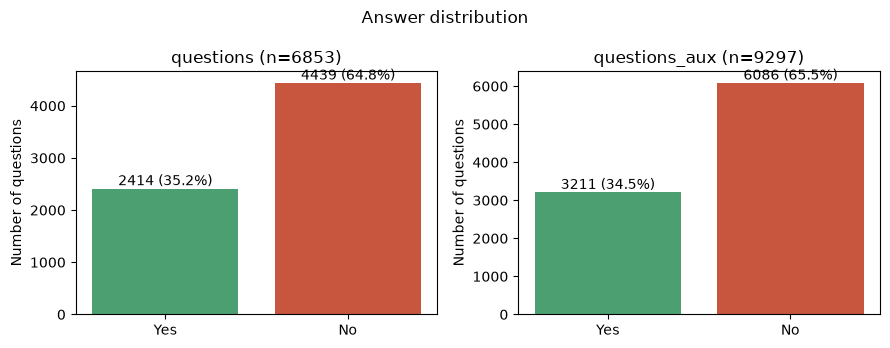

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=False)
for ax, (name, d) in zip(axes, [("questions", df), ("questions_aux", dfa)]):
    counts = d["answer"].value_counts().reindex(["Yes", "No"])
    bars = ax.bar(counts.index, counts.values, color=["#4C9F70", "#C8553D"])
    ax.bar_label(bars, labels=[f"{v} ({v / len(d):.1%})" for v in counts.values])
    ax.set_title(f"{name} (n={len(d)})")
    ax.set_ylabel("Number of questions")
fig.suptitle("Answer distribution")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "answer_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** lệch lớp rõ: **No ≈ 64,8%**, Yes ≈ 35,2%. Baseline "luôn trả lời no" đã đạt khoảng 65% accuracy, nên Macro-F1 là metric chính để lộ ra mô hình chỉ đoán lớp đa số.

## 3. Số câu hỏi mỗi bang

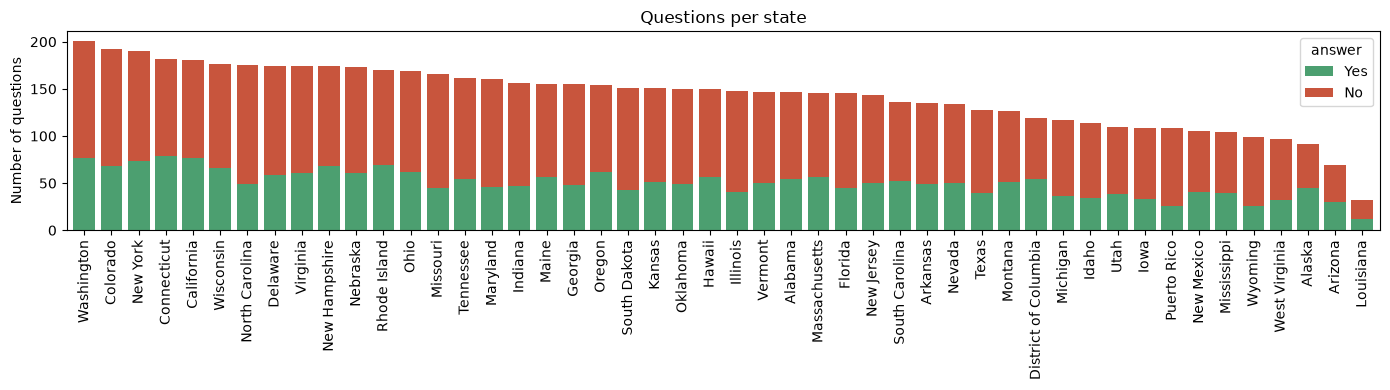

count     48.0
mean     142.8
std       33.9
min       32.0
25%      118.5
50%      149.0
75%      169.2
max      201.0
dtype: float64

In [7]:
per_state = df.groupby("state")["answer"].value_counts().unstack(fill_value=0)[["Yes", "No"]]
per_state = per_state.loc[per_state.sum(axis=1).sort_values(ascending=False).index]

ax = per_state.plot(kind="bar", stacked=True, figsize=(14, 4), color=["#4C9F70", "#C8553D"], width=0.8)
ax.set_title("Questions per state")
ax.set_xlabel("")
ax.set_ylabel("Number of questions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "questions_per_state.png", dpi=150, bbox_inches="tight")
plt.show()
per_state.sum(axis=1).describe().round(1)

**Nhận xét:** mỗi bang có 32–201 câu (trung bình 143 trên 226 nhóm), tức là không phải câu hỏi nào cũng có cho mọi bang.

## 4. `question_group`

In [8]:
group_sizes = df.groupby("question_group").size()
texts_per_group = df.groupby("question_group")["question"].nunique()
print("Số nhóm:", len(group_sizes))
print("Kích thước nhóm (số bang):", group_sizes.describe().round(1).to_dict())
print("Nhóm có hơn 1 cách viết câu hỏi:", int((texts_per_group > 1).sum()))

Số nhóm: 226
Kích thước nhóm (số bang): {'count': 226.0, 'mean': 30.3, 'std': 12.6, 'min': 2.0, '25%': 21.0, '50%': 36.0, '75%': 42.0, 'max': 43.0}
Nhóm có hơn 1 cách viết câu hỏi: 0


In [9]:
# Cùng một câu hỏi lặp lại ở nhiều bang, đáp án khác nhau theo bang.
example_group = df.groupby("question_group")["answer"].nunique().pipe(lambda s: s[s > 1]).index[0]
print("question:", df.loc[df["question_group"] == example_group, "question"].iloc[0])
df.loc[df["question_group"] == example_group, ["state", "answer"]].head(8)

question: Can a landlord evict a tenant because they seek to use the property for personal use?


,state,answer
25,Alabama,No
178,Alaska,Yes
268,Arizona,No
339,Arkansas,No
478,California,Yes
659,Colorado,No
853,Connecticut,Yes
1030,Delaware,No


In [10]:
group_majority = df.groupby("question_group")["answer"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"Tỉ lệ trung bình của đáp án đa số trong nhóm: {group_majority.mean():.3f}")
print(f"Nhóm mà ≥90% bang cùng đáp án: {(group_majority >= 0.9).mean():.1%}")
print(f"Nhóm mà tất cả các bang cùng đáp án: {(group_majority == 1).mean():.1%}")

Tỉ lệ trung bình của đáp án đa số trong nhóm: 0.849
Nhóm mà ≥90% bang cùng đáp án: 50.9%
Nhóm mà tất cả các bang cùng đáp án: 19.0%


**Nhận xét:** mỗi `question_group` là **một câu hỏi giống hệt nhau từng chữ** lặp lại ở 2–43 bang, đáp án đổi theo bang, nên phải ghép tên bang vào đầu vào. Khoảng 51% nhóm có ≥90% bang cùng đáp án: nếu chia ngẫu nhiên, mô hình chỉ cần nhớ dạng câu hỏi là đúng, vì vậy phải chia theo nhóm.

## 5. Độ dài câu hỏi

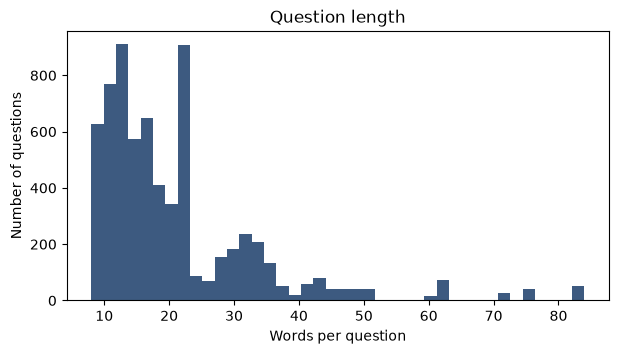

count    6853.0
mean       20.8
std        13.0
min         8.0
50%        17.0
90%        35.0
99%        76.0
max        84.0
Name: question, dtype: float64

In [11]:
q_words = df["question"].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(q_words, bins=40, color="#3D5A80")
ax.set_xlabel("Words per question")
ax.set_ylabel("Number of questions")
ax.set_title("Question length")
fig.savefig(FIGURES_DIR / "question_length.png", dpi=150, bbox_inches="tight")
plt.show()
q_words.describe(percentiles=[0.5, 0.9, 0.99]).round(1)

**Nhận xét:** câu hỏi ngắn (trung vị 17 từ, dài nhất 84 từ), độ dài sau tokenize xem ở notebook 02.

## 6. Gold statute

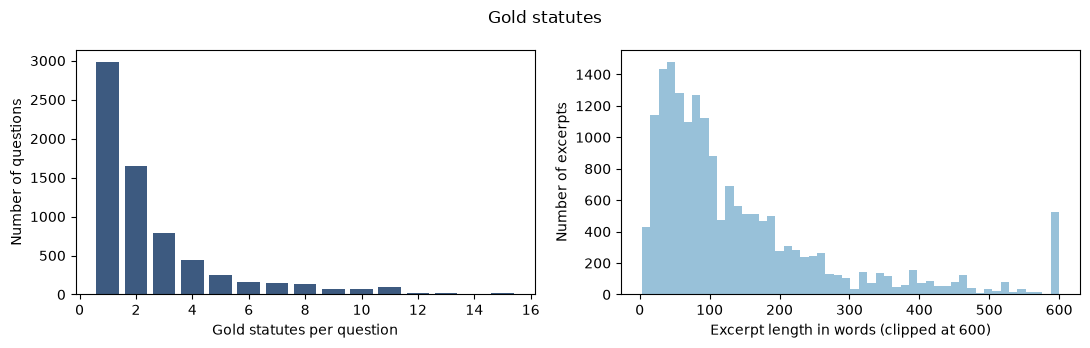

Số điều luật căn cứ / câu: {'count': 6853.0, 'mean': 2.61, 'std': 2.39, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 15.0}
Số từ excerpt: {'count': 17862.0, 'mean': 152.8, 'std': 193.8, 'min': 3.0, '50%': 94.0, '90%': 336.0, '99%': 971.0, 'max': 2718.0}
Số gold statute khác nhau: 990 / tổng lượt tham chiếu: 17862


In [12]:
n_statutes = df["statutes"].map(len)
excerpt_words = pd.Series([len(s["excerpt"].split()) for row in Q for s in row["statutes"]])
gold_ids = [s["statute_idx"] for row in Q for s in row["statutes"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(*zip(*sorted(Counter(n_statutes).items())), color="#3D5A80")
axes[0].set_xlabel("Gold statutes per question")
axes[0].set_ylabel("Number of questions")
axes[1].hist(excerpt_words.clip(upper=600), bins=50, color="#98C1D9")
axes[1].set_xlabel("Excerpt length in words (clipped at 600)")
axes[1].set_ylabel("Number of excerpts")
fig.suptitle("Gold statutes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gold_statutes.png", dpi=150, bbox_inches="tight")
plt.show()

print("Số điều luật căn cứ / câu:", n_statutes.describe().round(2).to_dict())
print("Số từ excerpt:", excerpt_words.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_dict())
print("Số gold statute khác nhau:", len(set(gold_ids)), "/ tổng lượt tham chiếu:", len(gold_ids))

**Nhận xét:** mỗi câu có 1–15 điều luật căn cứ (trung vị 2), tổng cộng 990 điều luật khác nhau. Excerpt có trung vị 94 từ, p90 336 từ: dùng để chọn kích thước chunk ở notebook 03.

## 7. Câu hỏi trùng lặp và nhãn mâu thuẫn

In [13]:
dup = df[df.duplicated(subset=["state", "question"], keep=False)]
print("Số dòng trùng (state, question):", len(dup))
dup[["idx", "state", "question_group", "answer", "question"]]

Số dòng trùng (state, question): 9


,idx,state,question_group,answer,question
995,9206,Connecticut,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?
996,9207,Connecticut,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?
997,9208,Connecticut,196,Yes,Does the state/territory have a law regarding mediation proceedings for evictions?
1288,9209,District of Columbia,196,Yes,Does the state/territory have a law regarding mediation proceedings for evictions?
1289,9210,District of Columbia,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?
1290,9211,District of Columbia,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?
6469,9218,Washington,196,Yes,Does the state/territory have a law regarding mediation proceedings for evictions?
6470,9219,Washington,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?
6471,9220,Washington,196,No,Does the state/territory have a law regarding mediation proceedings for evictions?


**Nhận xét:** 9 dòng của nhóm 196 (Connecticut, District of Columbia, Washington) giống hệt nhau cả câu hỏi lẫn điều luật nhưng đáp án mâu thuẫn (Yes/No/No). Đây là nhiễu nhãn, notebook 02 bỏ các dòng này.

## 8. Ví dụ QA tiêu biểu (cho report)

In [14]:
def short_excerpt(row, max_words=80):
    s = row["statutes"][0]
    return len(row["statutes"]) == 1 and len(s["excerpt"].split()) <= max_words

candidates = df[df.apply(short_excerpt, axis=1)].drop_duplicates("question_group")
examples = pd.concat([
    candidates[candidates["answer"] == "Yes"].sample(2, random_state=42),
    candidates[candidates["answer"] == "No"].sample(3, random_state=42),
])
qa_examples = pd.DataFrame({
    "state": examples["state"],
    "question": examples["question"],
    "answer": examples["answer"],
    "citation": examples["statutes"].map(lambda s: s[0]["citation"]),
    "excerpt": examples["statutes"].map(lambda s: s[0]["excerpt"]),
})
qa_examples.to_csv(TABLES_DIR / "qa_examples.csv", index=False)
for r in qa_examples.itertuples():
    print(f"[{r.state}] Q: {r.question}\n  A: {r.answer} | {r.citation}\n  {r.excerpt}\n")

[District of Columbia] Q: Is it specified in which court eviction cases are first heard?
  A: Yes | D.C. CODE § 42-3210
  Whenever a lease for any definite term shall expire, or any tenancy shall be terminated by notice as aforesaid, and the tenant shall fail or refuse to surrender possession of the leased premises, the landlord may bring an action of ejectment to recover possession in the Superior Court of the District of Columbia.

[Alaska] Q: Is it specified for what reasons a landlord must halt the eviction process after filing but prior to the judgment?
  A: Yes | ALASKA STAT. § 9.45.690
  If, at any time before judgment, the lessee or a successor in interest pays the amount of rent in arrears with interest and costs of the action and performs the other covenants or agreements, the lessee or successor is entitled to continue in possession unless otherwise provided in the lease.

[Delaware] Q: Does inclement weather postpone the execution of a writ of eviction?
  A: No | DEL CODE T

## 9. Hạn chế của dataset (đưa vào report)

- Luật chỉ đúng **đến năm 2021**, không phải tư vấn pháp lý hiện hành.
- **Không đủ bang**: `questions` có 48 bang, mỗi câu hỏi chỉ có ở 2–43 bang; 7 bang/lãnh thổ chỉ có trong `questions_aux`.
- **Kho điều luật không bao phủ hết**: chỉ một phần điều luật mỗi bang được thu thập, và không phải mọi điều luật trong `statutes` đều cần cho câu trả lời (theo README dataset).
- **Đáp án chỉ Yes/No** và lệch về No (~65%): đáp ứng "short answer" nhưng không đo được khả năng sinh câu trả lời dài.
- **Nhiễu nhãn**: có dòng trùng nhưng đáp án mâu thuẫn (nhóm 196); nhiều câu có `caveats` (1.512 câu) cho thấy đáp án Yes/No là đơn giản hoá.